Name: Raj Gajare

Sec-Bat : B3-B4

Roll No: 56

SI Lab Practical -8 Part-B Classification models

Aim : Type 2 Diabetes Risk Prediction. Implement all traditional classfication algorithm .

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    VotingClassifier,
    StackingClassifier
)
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

In [36]:
df = pd.read_csv("diabetes_prediction_dataset.csv")

print("First 5 Rows:")
print(df.head())

print("\nLast 5 Rows:")
print(df.tail())

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())
print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())


First 5 Rows:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  

Last 5 Rows:
       gender   age  hypertension  heart_disease smoking_history    bmi  \
99995  Female  80.0             0              0         No Info  27.32   
99996  Female   2.0             0              0         No Info  17.37   
99997    Male  66.0             

In [37]:

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_columns = df.select_dtypes(
    include=['object']
).columns

print("\nNumerical Columns:")
print(numerical_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())

print("\nStatistical Summary:")
print(df.describe())



Numerical Columns:
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Categorical Columns:
['gender', 'smoking_history']

Statistical Summary:
                 age  hypertension  heart_disease            bmi  \
count  100000.000000  100000.00000  100000.000000  100000.000000   
mean       41.885856       0.07485       0.039420      27.320767   
std        22.516840       0.26315       0.194593       6.636783   
min         0.080000       0.00000       0.000000      10.010000   
25%        24.000000       0.00000       0.000000      23.630000   
50%        43.000000       0.00000       0.000000      27.320000   
75%        60.000000       0.00000       0.000000      29.580000   
max        80.000000       1.00000       1.000000      95.690000   

         HbA1c_level  blood_glucose_level       diabetes  
count  100000.000000        100000.000000  100000.000000  
mean        5.527507           138.058060       0.085000  
std         1.0706

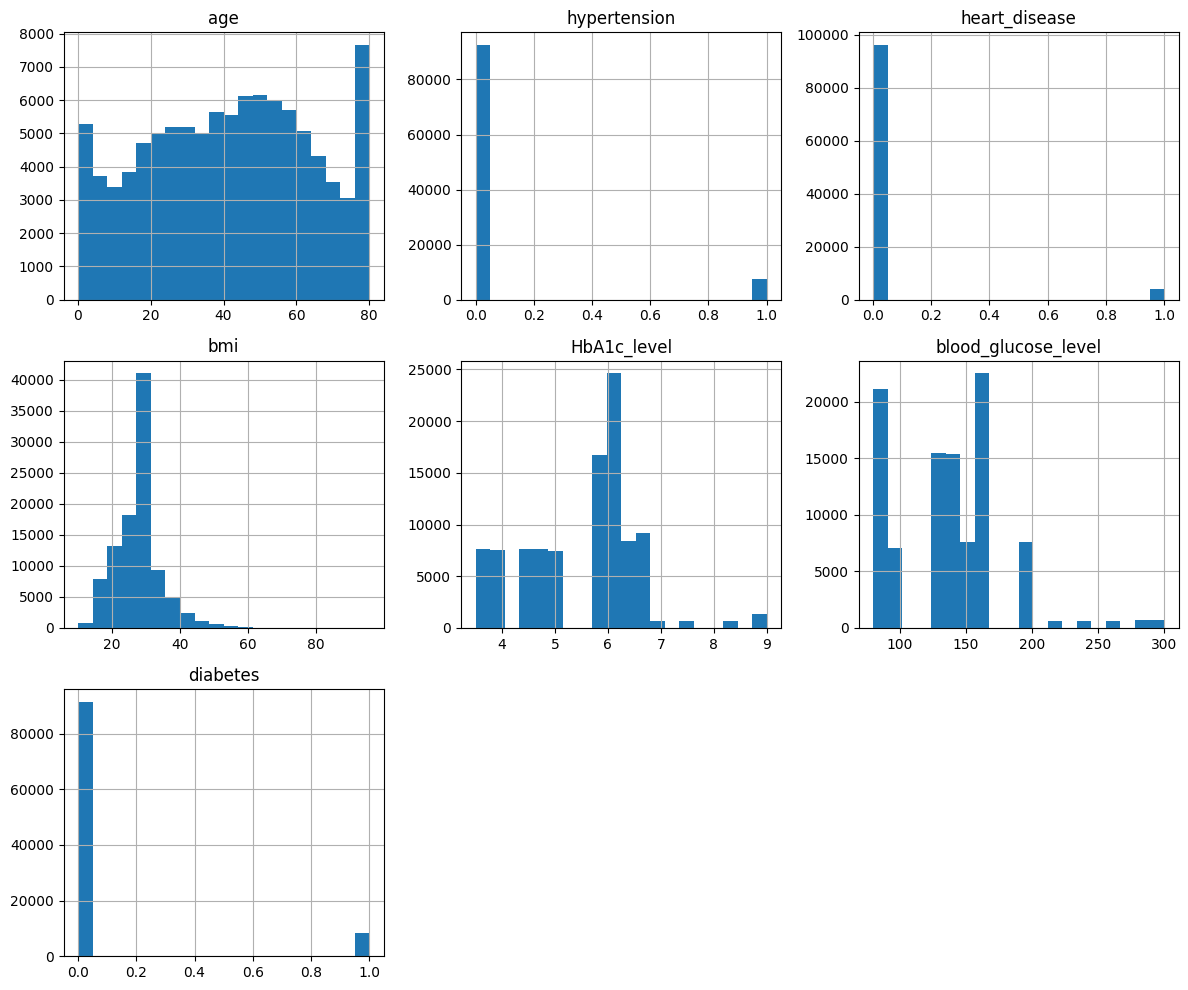

In [38]:
# Histogram
df[numerical_columns].hist(
    figsize=(12, 10),
    bins=20
)

plt.tight_layout()
plt.show()

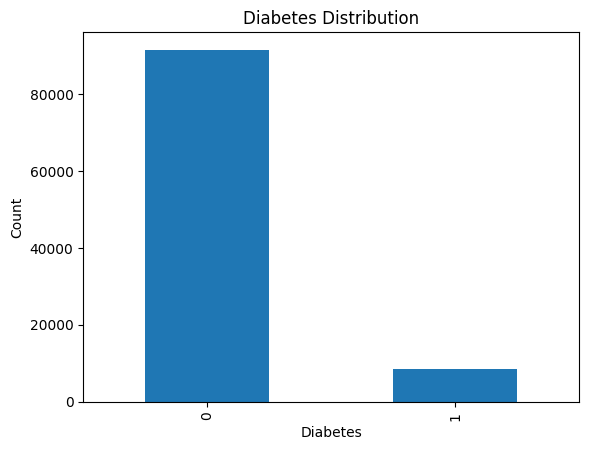

In [39]:
# Diabetes distribution
df['diabetes'].value_counts().plot(kind='bar')
plt.xlabel("Diabetes")
plt.ylabel("Count")
plt.title("Diabetes Distribution")
plt.show()

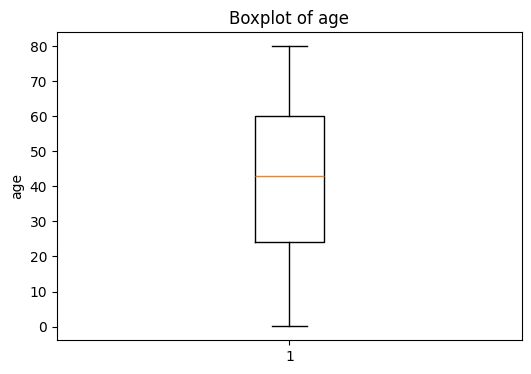

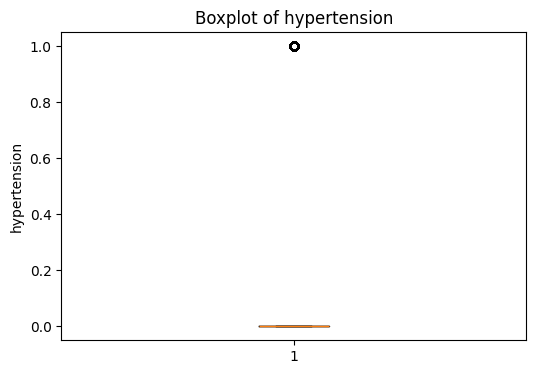

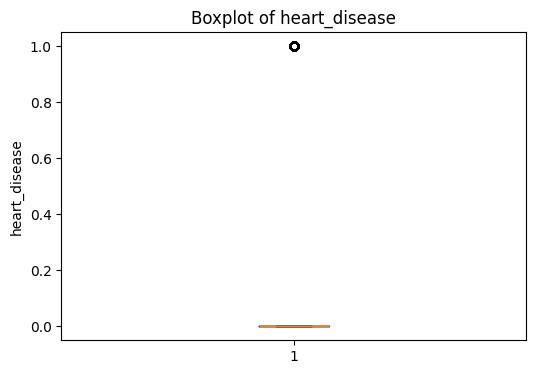

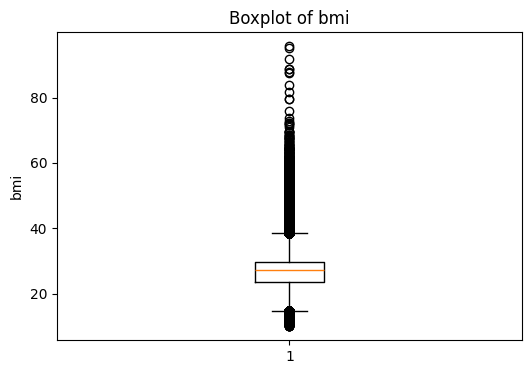

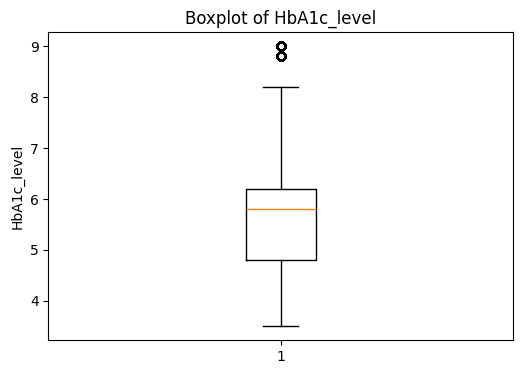

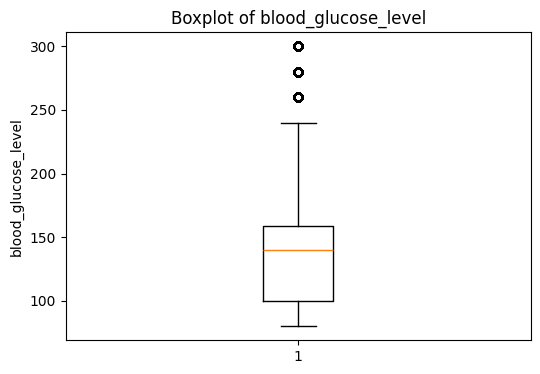

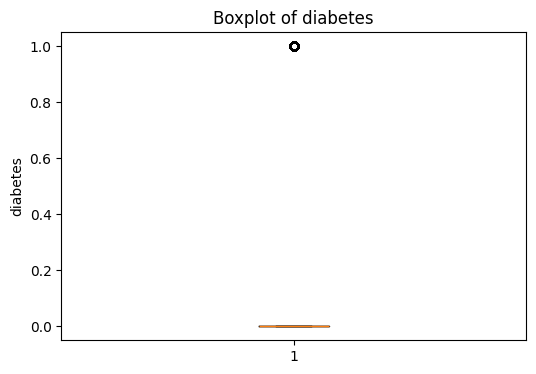

In [40]:
for column in numerical_columns:

    plt.figure(figsize=(6, 4))

    plt.boxplot(df[column])

    plt.title("Boxplot of " + column)
    plt.ylabel(column)

    plt.show()

5. DATA PREPROCESSING

In [41]:
# Handle missing numerical values
for column in numerical_columns:

    if df[column].isnull().sum() > 0:

        df[column] = df[column].fillna(
            df[column].median()
        )


# Handle missing categorical values
for column in categorical_columns:

    if df[column].isnull().sum() > 0:

        df[column] = df[column].fillna(
            df[column].mode()[0]
        )

In [42]:
df = df.drop_duplicates()

print("\nDuplicates after removal:")
print(df.duplicated().sum())
df = pd.get_dummies(df, drop_first=True)

# Independent variables
X = df.drop('diabetes',axis=1)

# Dependent variable
y = df['diabetes']

print("\nIndependent Variables:")
print(X.columns.tolist())

print("\nDependent Variable:")
print(y.name)

print("\nX Shape:")
print(X.shape)

print("\ny Shape:")
print(y.shape)


Duplicates after removal:
0

Independent Variables:
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Male', 'gender_Other', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']

Dependent Variable:
diabetes

X Shape:
(96146, 13)

y Shape:
(96146,)


6. CORRELATION ANALYSIS

In [43]:
correlation_matrix = df.corr()

print("\nCorrelation Matrix:")
print(correlation_matrix)


Correlation Matrix:
                                  age  hypertension  heart_disease       bmi  \
age                          1.000000      0.257305       0.238451  0.344797   
hypertension                 0.257305      1.000000       0.119982  0.148111   
heart_disease                0.238451      0.119982       1.000000  0.061376   
bmi                          0.344797      0.148111       0.061376  1.000000   
HbA1c_level                  0.106719      0.081441       0.068140  0.084423   
blood_glucose_level          0.114317      0.084834       0.070832  0.092543   
diabetes                     0.264927      0.195710       0.170711  0.214932   
gender_Male                 -0.028580      0.014240       0.078539 -0.023488   
gender_Other                -0.007456     -0.003969      -0.002822  0.000117   
smoking_history_current      0.033424      0.015637       0.006031  0.053933   
smoking_history_ever         0.068179      0.021178       0.039469  0.044396   
smoking_history_for

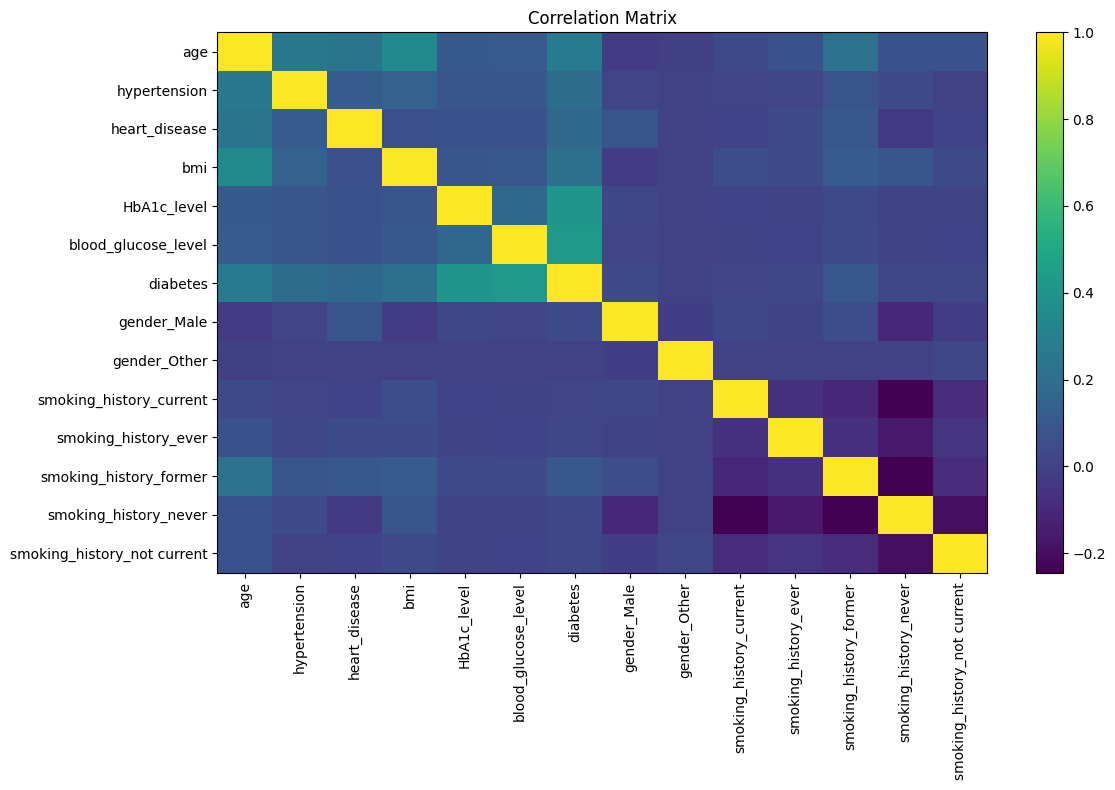

In [44]:
plt.figure(figsize=(12, 8))
plt.imshow(correlation_matrix,aspect='auto')
plt.colorbar()
plt.xticks(range(len(correlation_matrix.columns)),correlation_matrix.columns,rotation=90)
plt.yticks(range(len(correlation_matrix.columns)),correlation_matrix.columns)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

7. COVARIANCE ANALYSIS


Covariance Matrix:
                            age  hypertension  heart_disease        bmi  \
age                  504.584014      1.546357       1.059658  52.416958   
hypertension           1.546357      0.071580       0.006351   0.268178   
heart_disease          1.059658      0.006351       0.039138   0.082175   
bmi                   52.416958      0.268178       0.082175  45.801974   
HbA1c_level            2.572780      0.023385       0.014467   0.613190   
blood_glucose_level  105.051869      0.928522       0.573268  25.621901   
diabetes               1.687810      0.014850       0.009578   0.412547   

                     HbA1c_level  blood_glucose_level  diabetes  
age                     2.572780           105.051869  1.687810  
hypertension            0.023385             0.928522  0.014850  
heart_disease           0.014467             0.573268  0.009578  
bmi                     0.613190            25.621901  0.412547  
HbA1c_level             1.151827             7.53

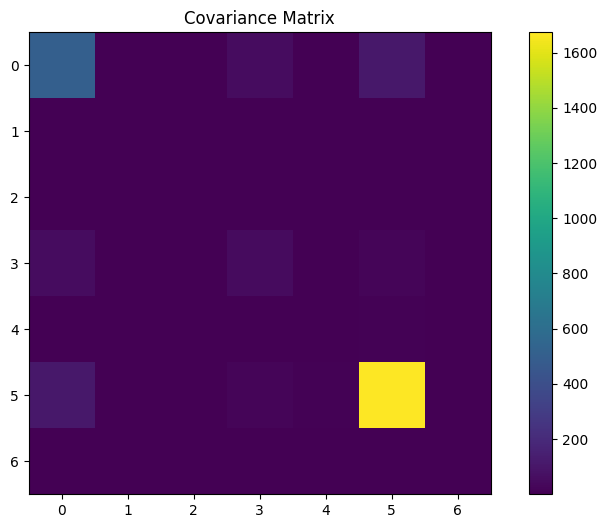

In [45]:
numerical_data = df.select_dtypes(
    include=['int64', 'float64']
)
covariance = numerical_data.cov()

print("\nCovariance Matrix:")
print(covariance)


plt.figure(figsize=(10, 6))
plt.imshow(covariance)
plt.colorbar()
plt.title("Covariance Matrix")
plt.show()

8. TRAIN TEST SPLIT

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Data:")
print(X_train.shape)

print("\nTesting Data:")
print(X_test.shape)


Training Data:
(76916, 13)

Testing Data:
(19230, 13)


9. FEATURE SCALING

In [47]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

print("\nFeature Scaling Completed.")


Feature Scaling Completed.


In [48]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000
mean,41.794326,0.077601,0.040803,27.321461,5.532609,138.218231,0.088220
std,22.462948,0.267544,0.197833,6.767716,1.073232,40.909771,0.283616
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.000000,0.000000,23.400000,4.800000,100.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,59.000000,0.000000,0.000000,29.860000,6.200000,159.000000,0.000000
max,80.000000,1.000000,1.000000,95.690000,9.000000,300.000000,1.000000


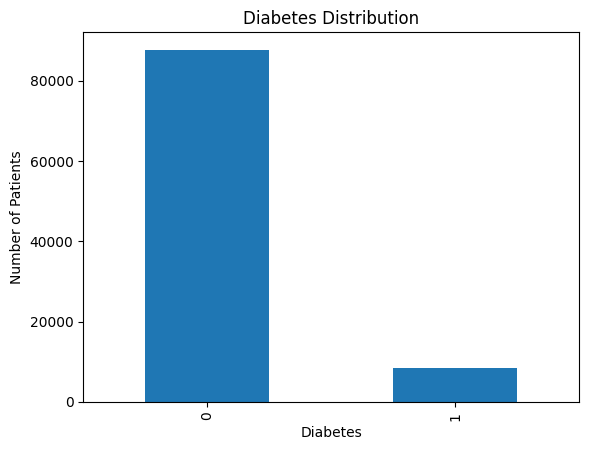

In [49]:
# Distribution of diabetes

df['diabetes'].value_counts().plot(kind='bar')

plt.title('Diabetes Distribution')
plt.xlabel('Diabetes')
plt.ylabel('Number of Patients')

plt.show()

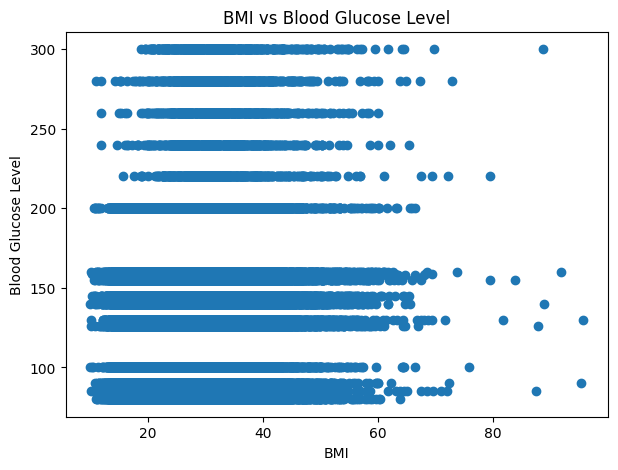

In [50]:
# Scatter plot

plt.figure(figsize=(7, 5))

plt.scatter(df['bmi'], df['blood_glucose_level'])

plt.title('BMI vs Blood Glucose Level')
plt.xlabel('BMI')
plt.ylabel('Blood Glucose Level')

plt.show()

 10. LOGISTIC REGRESSION

In [51]:
logistic_model = LogisticRegression()

logistic_model.fit(X_train_scaled,y_train)
y_pred_logistic = logistic_model.predict(X_test_scaled)

logistic_accuracy = accuracy_score(y_test,y_pred_logistic)

print("\nLogistic Regression Accuracy:")
print(logistic_accuracy)

print("\nClassification Report:")
print(classification_report(y_test,y_pred_logistic))


Logistic Regression Accuracy:
0.9570982839313572

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98     17509
           1       0.85      0.63      0.72      1721

    accuracy                           0.96     19230
   macro avg       0.91      0.81      0.85     19230
weighted avg       0.95      0.96      0.95     19230



11. KNN

In [52]:
# KNN Classifier
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 0.9580863234529381

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98     17509
           1       0.88      0.61      0.72      1721

    accuracy                           0.96     19230
   macro avg       0.92      0.80      0.85     19230
weighted avg       0.96      0.96      0.95     19230



12. SVM

In [53]:
# Support Vector Model
svm_model = SVC()
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.960374414976599

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     17509
           1       0.97      0.58      0.72      1721

    accuracy                           0.96     19230
   macro avg       0.96      0.79      0.85     19230
weighted avg       0.96      0.96      0.96     19230



13. DECISION TREE

In [54]:
# Decision Tree Classifier
decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(X_train, y_train)
y_pred_tree = decision_tree_model.predict(X_test)
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", tree_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

Decision Tree Accuracy: 0.9485699427977119

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     17509
           1       0.70      0.74      0.72      1721

    accuracy                           0.95     19230
   macro avg       0.84      0.85      0.85     19230
weighted avg       0.95      0.95      0.95     19230



14. RANDOM FOREST

In [55]:
# Random Forest Classifier
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
random_forest_model.fit(X_train, y_train)
y_pred_rf = random_forest_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.96801872074883

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17509
           1       0.94      0.69      0.79      1721

    accuracy                           0.97     19230
   macro avg       0.96      0.84      0.89     19230
weighted avg       0.97      0.97      0.97     19230



15. NAIVE BAYES

In [56]:
# Naive Bayes Classifier
naive_bayes_model = GaussianNB()
naive_bayes_model.fit(X_train, y_train)
y_pred_nb = naive_bayes_model.predict(X_test)
nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", nb_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.861622464898596

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.87      0.92     17509
           1       0.37      0.79      0.51      1721

    accuracy                           0.86     19230
   macro avg       0.67      0.83      0.71     19230
weighted avg       0.92      0.86      0.88     19230



16. XGBOOST

In [57]:

xgb_model = XGBClassifier(n_estimators=100,max_depth=5,learning_rate=0.1,random_state=42,eval_metric='logloss')
xgb_model.fit(X_train_scaled,y_train)
y_pred_xgb = xgb_model.predict(X_test_scaled)
xgb_accuracy = accuracy_score(y_test,y_pred_xgb)
print("\nXGBoost Accuracy:")
print(xgb_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_xgb
    )
)


XGBoost Accuracy:
0.9710348413936557

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17509
           1       0.99      0.68      0.81      1721

    accuracy                           0.97     19230
   macro avg       0.98      0.84      0.90     19230
weighted avg       0.97      0.97      0.97     19230



17. VOTING CLASSIFIER

In [58]:
voting_model = VotingClassifier(
    estimators=[
        ('lr', LogisticRegression()),
        ('knn', KNeighborsClassifier(n_neighbors=5)),
        ('svm', SVC())
    ],
    voting='hard'
)

voting_model.fit(X_train_scaled,y_train)

y_pred_voting = voting_model.predict(X_test_scaled)

voting_accuracy = accuracy_score(y_test,y_pred_voting)

print("\nVoting Classifier Accuracy:")
print(voting_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_voting
    )
)


Voting Classifier Accuracy:
0.9609984399375975

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     17509
           1       0.95      0.60      0.73      1721

    accuracy                           0.96     19230
   macro avg       0.96      0.80      0.86     19230
weighted avg       0.96      0.96      0.96     19230



18. STACKING CLASSIFIER

In [59]:
stacking_model = StackingClassifier(
    estimators=[
        ('lr', LogisticRegression()),
        ('knn', KNeighborsClassifier(n_neighbors=5)),
        ('dt', DecisionTreeClassifier(random_state=42))
    ],
    final_estimator=LogisticRegression()
)

stacking_model.fit(X_train_scaled,y_train)
y_pred_stacking = stacking_model.predict(X_test_scaled)
stacking_accuracy = accuracy_score(y_test,y_pred_stacking)
print("\nStacking Classifier Accuracy:")
print(stacking_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_stacking
    )
)


Stacking Classifier Accuracy:
0.9627665106604264

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17509
           1       0.89      0.67      0.76      1721

    accuracy                           0.96     19230
   macro avg       0.93      0.83      0.87     19230
weighted avg       0.96      0.96      0.96     19230



19. MODEL COMPARISON

In [60]:
results = pd.DataFrame({
    "Model": ["Logistic Regression",
        "KNN",
        "SVM",
        "Decision Tree",
        "Random Forest",
        "Naive Bayes",
        "XGBoost",
        "Voting Classifier",
        "Stacking Classifier"
    ],
    "Accuracy": [
        logistic_accuracy,
        knn_accuracy,
        svm_accuracy,
        tree_accuracy,
        rf_accuracy,
        nb_accuracy,
        xgb_accuracy,
        voting_accuracy,
        stacking_accuracy
    ]
})

In [61]:
model_list = [
    logistic_model,
    knn_model,
    svm_model,
    decision_tree_model,
    random_forest_model,
    naive_bayes_model,
    xgb_model,
    voting_model,
    stacking_model
]
best_index = results["Accuracy"].idxmax()
final_model = model_list[best_index]
best_model_name = results.loc[
    best_index,
    "Model"
]
best_accuracy = results.loc[
    best_index,
    "Accuracy"
]
print("Best Model:")
print(best_model_name)

print("\nBest Accuracy:")
print(best_accuracy)

Best Model:
XGBoost

Best Accuracy:
0.9710348413936557


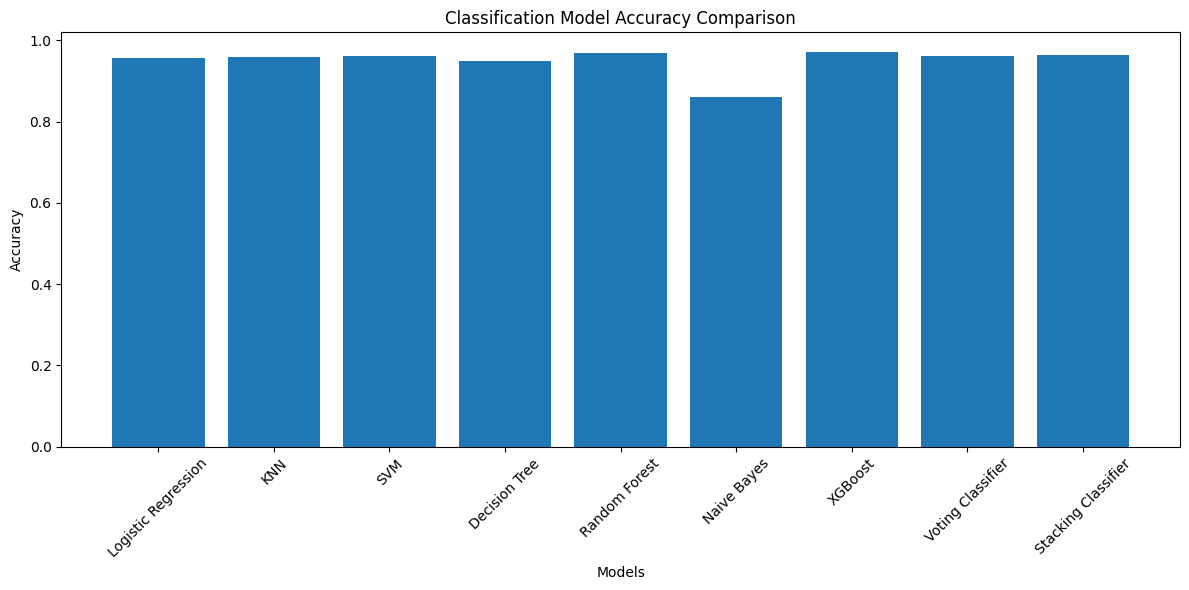

In [62]:
plt.figure(figsize=(12, 6))
plt.bar(results["Model"],results["Accuracy"])
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Classification Model Accuracy Comparison")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [63]:
joblib.dump(
    final_model,
    "diabetes_model.pkl"
)
print("\nBest model saved as:")
print("diabetes_model.pkl")


Best model saved as:
diabetes_model.pkl


In [64]:
joblib.dump(
    scaler,
    "scaler.pkl"
)

print("\nScaler saved as:")
print("scaler.pkl")


Scaler saved as:
scaler.pkl


In [65]:
feature_columns = X.columns.tolist()
joblib.dump(feature_columns,"feature_columns.pkl")
print("\nFeature columns saved as:")
print("feature_columns.pkl")


Feature columns saved as:
feature_columns.pkl


In [66]:
joblib.dump(best_model_name,"model_name.pkl")
print("\nModel name saved as:")
print("model_name.pkl")


Model name saved as:
model_name.pkl


In [69]:
import os

print(os.listdir())
print("\nRequired files:")
print("1. diabetes_model.pkl")
print("2. scaler.pkl")
print("3. feature_columns.pkl")
print("4. model_name.pkl")

['.config', 'diabetes_model.pkl', 'feature_columns.pkl', 'diabetes_prediction_dataset.csv', 'model_name.pkl', 'scaler.pkl', 'sample_data']

Required files:
1. diabetes_model.pkl
2. scaler.pkl
3. feature_columns.pkl
4. model_name.pkl
